# M2b · Latent LayerNorms with a directly trained head

**What M2 showed** (video AUC %, 10 epochs, seen = DF+F2F+FS+NT combined):

| model | trained numbers | seen | FaceShifter (unseen) |
|---|---|---|---|
| M1 full LN tuning, epoch 10 | 104,450 | 97.60 | 88.19 |
| M2 latent (LN + head), d = 64 | 65 | 46.56 | 55.56 |
| M2 latent (LN + head), d = 1024 | 1,025 | 72.63 | 67.58 |
| M2 latent (LN + head), d = 4096 | 4,097 | 96.80 | 78.72 |

With the head inside the random latent, d ≤ 256 learned only the class ratio: training cross-entropy ≈ 1.3 on reals and ≈ 0.3 on every fake, which is what predicting "fake" for everything gives on 1 : 4 data. The likely reason: the head must point in one specific direction of the 1024-d feature space, but in the latent it receives only ~2% of each random direction (the other 98% moves LayerNorms), it can only move within a random d-dim slice of its 2,048 weights, and every head move drags LayerNorm noise along. In addition, M2's probe chose the learning rate by total loss, which was dominated by the uniformity term rather than classification.

**Change in M2b.** Only the 102,400 LayerNorm numbers are generated, θ_LN = θ0_LN + α · W z. The head (2,050 numbers) is an ordinary trained parameter as in M1, with M1's learning rate. Deployed: 2,050 + d + 1 numbers + seed (about 8 KB). In GBLA, the per-generator latents act on the LayerNorms and the head is shared.

**Runs** (10 epochs each, same data, loss, augmentation and schedule as M1/M2):

- **head only** (d = 0): frozen CLIP + trained head. Tells how much LayerNorm adaptation adds at all.
- **latent LayerNorms**, d = 64, 1024, 256, 4096.

The learning rate of z is probed again, now chosen by **cross-entropy**, with the head-only run as reference. The head's learning rate is M1's.

**What we look for:** where each d lands between head-only and full LN tuning, on seen generators and especially on FaceShifter; 5.2 reports this as "% of the gap recovered".

| Section | What it does | Run time |
|---|---|---|
| 1. Setup | settings, imports | seconds |
| 2. Data | crops into RAM (as in M2), loaders, loading speed | ~3 min |
| 3. Model | detector with latent LayerNorms, checks, parameter report | ~2 min |
| 4. Training | learning-rate probe (once), then the runs (resumable) | probe ~15 min; head only ~0.5 h; each d ~1.4 h; total ~6.5 h |
| 5. Evaluation | M1 reference, M2 vs M2b vs d, curves | ~5 min |
| 6. Send results back | push this notebook | – |

## 1. Setup

### 1.1 Settings

Same paths and recipe as M2. Runs go to `runs/m2b/`; M2's results are read from `runs/m2/` for comparison. `RUNS` is in priority order; `d = 0` is the head-only baseline.

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")   # same as M0 / M1 / M2
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M2_DIR = RUNS_ROOT / "m2"       # M2 = head inside the latent (comparison only)
M2B_DIR = RUNS_ROOT / "m2b"

# protocol (same as M1)
ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]   # FaceShifter = unseen
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}

# model, loss, optimisation (same as M1)
ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
SEED = 0

# M2b: theta_LN = theta0_LN + alpha * W z for the LayerNorms; the head is trained directly
RUNS = [0, 64, 1024, 256, 4096]       # d = 0: head only; run order = priority
EPOCHS = 10
W_SEED = 2026
LR_HEAD_MAX, LR_HEAD_MIN = 3e-4, 1e-5          # the head's learning rate, as in M1
LR_Z_GRID = [3e-4, 1e-3, 3e-3, 1e-2, 3e-2]     # peak learning rates of z tried by the probe (4.2)
PROBE_D, PROBE_STEPS, PROBE_BATCHES = 64, 240, 60
LR_RATIO = 30                                   # minimum = peak / 30, as in M1

M1_RUN_DIR = RUNS_ROOT / "m1" / f"lnclip_{ARCH}_train-{'-'.join(SHORT[g] for g in TRAIN_GENERATORS)}_seed{SEED}"

# speed only (do not change the trained models)
VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

COMMON_CONFIG = {
    "arch": ARCH, "pretrained": PRETRAINED, "quick_gelu": True,
    "train_generators": TRAIN_GENERATORS, "l2_norm": L2_NORM,
    "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "cycle_epochs": CYCLE_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS, "seed": SEED,
    "latent_on": "LayerNorm only", "head": "trained directly",
    "lr_head_max": LR_HEAD_MAX, "lr_head_min": LR_HEAD_MIN,
}
assert INDEX_CSV.exists(), f"index not found: {INDEX_CSV} (run M0 first)"
assert (M1_RUN_DIR / "last.pt").exists(), f"M1 run not found: {M1_RUN_DIR}"
M2B_DIR.mkdir(parents=True, exist_ok=True)
print("M2b runs go to:", M2B_DIR)

M2b runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m2b


### 1.2 Imports and environment

`os.cpu_count()` reports the whole node (256), but the job may only use the CPUs in its affinity mask and cgroup quota; the loader uses that number. Free RAM decides in 2.2 how many crops can be kept in memory.

In [2]:
# 1.2 Imports and environment
import json, math, random, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M2b needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    """CPUs this job may use: the affinity mask and the cgroup CPU quota."""
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    """Free RAM for this job: the smaller of MemAvailable and the cgroup limit minus non-cache usage."""
    candidates = []
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        candidates.append(int(meminfo["MemAvailable"].split()[0]) * 1024)
    except (OSError, KeyError, ValueError):
        pass
    for limit_file, usage_file, stat_file, cache_key in [
            ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current", "/sys/fs/cgroup/memory.stat", "file"),
            ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes",
             "/sys/fs/cgroup/memory/memory.stat", "cache")]:
        try:
            limit = Path(limit_file).read_text().strip()
            if not limit.isdigit() or int(limit) >= 1 << 60:
                continue
            usage = int(Path(usage_file).read_text().strip())
            stat = dict(line.split() for line in Path(stat_file).read_text().splitlines())
            candidates.append(int(limit) - usage + int(stat.get(cache_key, 0)))
        except (OSError, ValueError):
            pass
    return min(candidates) / 1e9 if candidates else 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))     # one CPU stays with the training process
torch.set_num_threads(2)

pd.Series({
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPU cores on the node": os.cpu_count(),
    "CPUs usable by this job": CPUS,
    "data loader workers": NUM_WORKERS,
    "free RAM for this job (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
torchvision,0.21.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPU cores on the node,256
CPUs usable by this job,1
data loader workers,1
free RAM for this job (GB),1048.3


## 2. Data

### 2.1 Index and subsets

Same splits as M1: train = real + the 4 training generators (115,200 crops); test = real + all 5 generators, FaceShifter unseen. Val keeps 8 evenly spaced frames of each video (5,600 crops instead of 22,400). Val only monitors training, so this changes no trained model; val numbers are therefore not identical to M1's.

In [3]:
# 2.1 Index and subsets
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


train_df = subset("train", TRAIN_GENERATORS)
val_all = subset("val", TRAIN_GENERATORS)
frames_per_video = int(val_all.groupby(["generator", "video_id"]).size().max())
keep_every = max(1, frames_per_video // VAL_FRAMES_PER_VIDEO)
frame_rank = val_all.groupby(["generator", "video_id"]).frame_idx.rank(method="first").astype(int) - 1
val_df = val_all[frame_rank % keep_every == 0].reset_index(drop=True)
test_df = subset("test", ALL_GENERATORS)

display(pd.DataFrame({name: df.groupby("generator").size().reindex(CATEGORIES)
                      for name, df in [("train", train_df), ("val (subsampled)", val_df), ("test", test_df)]}
                     ).fillna(0).astype(int))

,train,val (subsampled),test
generator,,,
original,23040,1120,4480
Deepfakes,23040,1120,4480
Face2Face,23040,1120,4480
FaceSwap,23040,1120,4480
NeuralTextures,23040,1120,4480
FaceShifter,0,0,4480


### 2.2 Decoded crops in RAM

Reading 115,200 small PNG files per epoch from the network file system was the likely M1 bottleneck. Here every crop is read once per session into one uint8 array (224 × 224 × 3 bytes per crop: train 17.3 GB, val 0.8 GB, test 4.0 GB), in the order train → val → test, as long as it fits in 60% of free RAM. Sets that don't fit are read from disk as in M1. Nothing is written to disk. The printed read speed also tells us how fast the file system is.

In [4]:
# 2.2 Decoded crops in RAM
def load_images(df, desc):
    """Decodes every crop of an index slice into one uint8 array (N, H, W, 3), using threads."""
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} crops -> RAM")
        budget -= need
        sec = time.time() - t
        print(f"{name}: {len(df):,} crops, {need:.1f} GB in RAM, {sec / 60:.1f} min ({len(df) / sec:.0f} crops/s from disk)")
    else:
        images[name] = None
        print(f"{name}: read from disk during training (needs {need:.1f} GB, RAM budget left {budget:.1f} GB)")

train crops -> RAM: 100%|██████████| 115200/115200 [05:36<00:00, 342.03it/s]


train: 115,200 crops, 17.3 GB in RAM, 5.7 min (339 crops/s from disk)


val crops -> RAM: 100%|██████████| 5600/5600 [00:22<00:00, 248.72it/s]


val: 5,600 crops, 0.8 GB in RAM, 0.4 min (248 crops/s from disk)


test crops -> RAM: 100%|██████████| 26880/26880 [01:33<00:00, 288.25it/s]

test: 26,880 crops, 4.0 GB in RAM, 1.6 min (286 crops/s from disk)


### 2.3 Datasets and loaders

Same transforms, augmentations and seeded epoch order as M1. A dataset reads from the RAM array when there is one, otherwise from disk.

In [5]:
# 2.3 Datasets and loaders
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    """Returns (image, label, generator code) for every row of an index slice."""

    def __init__(self, df, train, images=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = images
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class EpochSampler(Sampler):
    """Random order that depends only on (seed, epoch), so resumed runs see the same order."""

    def __init__(self, n, seed):
        self.n, self.seed, self.epoch = n, seed, 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        g = torch.Generator().manual_seed(self.seed * 100_003 + self.epoch)
        return iter(torch.randperm(self.n, generator=g).tolist())

    def __len__(self):
        return self.n


train_ds = FaceDataset(train_df, train=True, images=images["train"])
train_sampler = EpochSampler(len(train_ds), SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, prefetch_factor=4)
print(f"steps per epoch: {len(train_loader)}, loader workers: {NUM_WORKERS}")

steps per epoch: 900, loader workers: 1


### 2.4 Data-loading speed

Measured properly this time: the batches the workers prepared in advance are taken out first, then 30 batches are timed. Also measured: the CPU time to prepare one augmented crop in a single process. If loading is slower than the GPU (M1: 253 img/s), the table says so; send me the output and I'll move the augmentations to the GPU.

In [6]:
# 2.4 Data-loading speed
def loader_rate(loader, n_batches=30):
    """Steady-state images/s after the pre-fetched batches are used up."""
    it = iter(loader)
    for _ in range(NUM_WORKERS * 4 + 2):
        next(it)
    t = time.time()
    for _ in range(n_batches):
        next(it)
    rate = n_batches * loader.batch_size / (time.time() - t)
    del it
    return rate


t = time.time()
for i in range(200):
    train_ds[i]
ms_per_crop = (time.time() - t) / 200 * 1000
load_speed = loader_rate(train_loader)
GPU_SPEED_M1 = 253
speed = min(load_speed, GPU_SPEED_M1)
pd.Series({
    "CPU time per augmented crop, one process (ms)": round(ms_per_crop, 1),
    "data loading speed (img/s)": round(load_speed),
    "GPU training speed in M1 (img/s)": GPU_SPEED_M1,
    "bottleneck": "GPU" if load_speed >= GPU_SPEED_M1 else "data loading",
    "estimated minutes per epoch (training part)": round(len(train_loader) * BATCH_SIZE / speed / 60, 1),
    f"estimated hours per d ({EPOCHS} epochs)": round(EPOCHS * len(train_loader) * BATCH_SIZE / speed / 3600, 1),
}, name="value").to_frame()

,value
"CPU time per augmented crop, one process (ms)",17.6
data loading speed (img/s),239
GPU training speed in M1 (img/s),253
bottleneck,data loading
estimated minutes per epoch (training part),8.0
estimated hours per d (10 epochs),1.3


## 3. Model

### 3.1 Detector: generated LayerNorms, trained head

Same detector and same initial head as M1/M2. The 100 LayerNorm tensors (50 LayerNorms × scale, shift) stop being parameters: their starting values form θ0 (P = 102,400 numbers, fixed order), and `write_theta` puts the current θ into the modules before every forward pass. The head stays an ordinary trainable `nn.Linear`; `HEAD0` keeps its initial values so that every run starts from the same head.

Check: with θ = θ0 the logits on 4 val crops (2 real, 2 fake) must equal those of the ordinary model.

In [7]:
# 3.1 Detector: generated LayerNorms, trained head
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None                      # keep the 1024-d CLS token
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        """Returns (logits, L2-normalized features)."""
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)
HEAD0 = {k: v.detach().clone() for k, v in model.head.state_dict().items()}
HEAD_N = sum(p.numel() for p in model.head.parameters())


def reset_head(state=None):
    model.head.load_state_dict(HEAD0 if state is None else state)


def head_state():
    return {k: v.detach().cpu().clone() for k, v in model.head.state_dict().items()}


# the generated tensors, in a fixed order: every LayerNorm (scale, shift)
TARGETS = [(name, module, attr) for name, module in model.named_modules()
           if isinstance(module, nn.LayerNorm) for attr in ("weight", "bias")]
TARGET_NAMES = [f"{name}.{attr}" for name, _, attr in TARGETS]
TARGET_SHAPES = [tuple(getattr(m, a).shape) for _, m, a in TARGETS]
THETA0 = torch.cat([getattr(m, a).detach().reshape(-1) for _, m, a in TARGETS]).float()
P = THETA0.numel()

check_ds = FaceDataset(pd.concat([val_df[val_df.label == 0].iloc[:2], val_df[val_df.label == 1].iloc[:2]]), train=False)
check_x = torch.stack([check_ds[k][0] for k in range(4)]).to(DEVICE)
check_y = check_ds.labels.to(DEVICE)
with torch.no_grad():
    ref_logits, _ = model(check_x)

for _, m, a in TARGETS:
    delattr(m, a)


def write_theta(theta):
    """Puts the flat vector theta (length P) into the LayerNorms."""
    offset = 0
    for (_, m, a), shape in zip(TARGETS, TARGET_SHAPES):
        n = math.prod(shape)
        setattr(m, a, theta[offset:offset + n].view(shape))
        offset += n


with torch.no_grad():
    write_theta(THETA0)
    new_logits, _ = model(check_x)
diff = (new_logits - ref_logits).abs().max().item()
print(f"generated tensors: {len(TARGETS)}, P = {P:,};  head trained directly: {HEAD_N:,} numbers")
print(f"max logit difference, generated vs ordinary parameters: {diff:.2e}")
assert diff < 1e-4, "write_theta does not reproduce the model"
if ARCH == "ViT-L-14":
    assert P == 102_400 and HEAD_N == 2_050

generated tensors: 100, P = 102,400;  head trained directly: 2,050 numbers
max logit difference, generated vs ordinary parameters: 0.00e+00


### 3.2 Latent adapter

Same as M2, now over the P = 102,400 LayerNorm numbers: z (d numbers, starts at 0), α (1 number, starts at 1), W (P × d, entries N(0, 1/d), rebuilt on the GPU from `W_SEED`, never saved). The fingerprint of W is stored in each run's config, so a later session that would rebuild a different W refuses to resume.

In [8]:
# 3.2 Latent adapter
def random_basis(d, seed):
    """W: P x d, entries N(0, 1/d). Regenerated from the seed on the GPU, never stored."""
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    return torch.randn(P, d, generator=g, device=DEVICE) / math.sqrt(d)


def w_fingerprint(W):
    return [round(W.double().sum().item(), 6), round(W[0, 0].item(), 8), round(W[-1, -1].item(), 8)]


class LatentAdapter(nn.Module):
    """theta = THETA0 + alpha * W z; trainable: z (d numbers) and alpha (1 number)."""

    def __init__(self, d, seed=W_SEED):
        super().__init__()
        self.d, self.seed = d, seed
        self.z = nn.Parameter(torch.zeros(d, device=DEVICE))
        self.alpha = nn.Parameter(torch.ones((), device=DEVICE))
        self.register_buffer("W", random_basis(d, seed), persistent=False)

    def theta(self):
        return THETA0 + self.alpha * (self.W @ self.z)

    def latent_state(self):
        return {"d": self.d, "seed": self.seed,
                "z": self.z.detach().cpu().clone(), "alpha": self.alpha.detach().cpu().clone()}

    def load_latent(self, state):
        assert state["d"] == self.d and state["seed"] == self.seed, "checkpoint is for another d or seed"
        self.z.data.copy_(state["z"].to(DEVICE))
        self.alpha.data.copy_(state["alpha"].to(DEVICE))

### 3.3 Correctness checks

Same checks as M2 (all passed there), on the LayerNorm-only latent:

1. with z = 0 the generated θ equals θ0 exactly;
2. W rebuilt from the seed is identical;
3. every one of the 100 LayerNorm tensors receives a non-zero gradient;
4. the gradient on z equals α · Wᵀ · (gradient on θ) (expected ~1e-7);
5. finite differences agree with autograd as the step shrinks (below 2% at some step).

In [9]:
# 3.3 Correctness checks
adapter = LatentAdapter(PROBE_D)
start_ok = torch.equal(adapter.theta().detach(), THETA0)
same_w = torch.equal(adapter.W, random_basis(PROBE_D, W_SEED))

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
with torch.no_grad():
    adapter.z.normal_(0, 0.05)


def check_loss():
    write_theta(adapter.theta())
    logits, _ = model(check_x)
    return F.cross_entropy(logits.double(), check_y)


theta_leaf = adapter.theta().detach().requires_grad_(True)
write_theta(theta_leaf)
logits, _ = model(check_x)
F.cross_entropy(logits.double(), check_y).backward()
grad_theta = theta_leaf.grad.detach()
sizes = [math.prod(s) for s in TARGET_SHAPES]
unused = [n for n, seg in zip(TARGET_NAMES, grad_theta.split(sizes)) if seg.abs().sum() == 0]

check_loss().backward()
grad_z = adapter.z.grad.detach().clone()
expected_z = adapter.alpha.detach() * (adapter.W.T @ grad_theta)
chain_err = ((grad_z - expected_z).norm() / expected_z.norm()).item()

direction = torch.randn(PROBE_D, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(1))
direction /= direction.norm()
autograd_slope = (grad_z @ direction).item()
fd_rows = []
with torch.no_grad():
    z0 = adapter.z.clone()
    for eps in [1e-2, 3e-3, 1e-3, 3e-4]:
        adapter.z.copy_(z0 + eps * direction)
        loss_plus = check_loss().item()
        adapter.z.copy_(z0 - eps * direction)
        loss_minus = check_loss().item()
        fd_slope = (loss_plus - loss_minus) / (2 * eps)
        fd_rows.append({"eps": eps, "finite-difference slope": fd_slope, "autograd slope": autograd_slope,
                        "relative error": abs(fd_slope - autograd_slope) / max(abs(fd_slope), abs(autograd_slope), 1e-12)})
    adapter.z.copy_(z0)
fd_table = pd.DataFrame(fd_rows)
best_fd_err = fd_table["relative error"].min()
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

display(pd.Series({
    "z = 0 gives theta0 exactly": start_ok,
    "W rebuilt from the seed is identical": same_w,
    f"W fingerprint (d = {PROBE_D})": w_fingerprint(adapter.W),
    "LayerNorm tensors without gradient": unused if unused else "none",
    "chain rule, relative difference": f"{chain_err:.2e}",
}, name="value").to_frame())
display(fd_table.style.format({"eps": "{:g}", "finite-difference slope": "{:.6g}",
                               "autograd slope": "{:.6g}", "relative error": "{:.2e}"}))
del adapter, theta_leaf
model.head.zero_grad(set_to_none=True)
torch.cuda.empty_cache()
assert start_ok and same_w, "start point or W regeneration failed"
assert not unused, f"these tensors get no gradient: {unused}"
assert chain_err < 1e-4, "gradient on z does not follow the chain rule"
assert best_fd_err < 0.02, "finite differences disagree with autograd at every step size: send the notebook"
print("LATENT CHECKS OK")

,value
z = 0 gives theta0 exactly,True
W rebuilt from the seed is identical,True
W fingerprint (d = 64),"[359.970886, -0.02268198, -0.10745972]"
LayerNorm tensors without gradient,none
"chain rule, relative difference",1.06e-06


,eps,finite-difference slope,autograd slope,relative error
0,0.01,-0.0012402,-0.00346435,6.42e-01
1,0.003,-0.00317506,-0.00346435,8.35e-02
2,0.001,-0.00342896,-0.00346435,1.02e-02
3,0.0003,-0.00344854,-0.00346435,4.56e-03


LATENT CHECKS OK


### 3.4 Parameter report

Frozen: the CLIP backbone and θ0 of the LayerNorms. Trained: the head (2,050) plus z and α (d + 1). W is generated from the seed (entries listed, not stored). "Deployed" = what has to be shipped besides the public CLIP weights.

In [10]:
# 3.4 Parameter report
def module_group(name):
    parts = name.split(".")
    if "attn" in parts:
        return "attention"
    if "mlp" in parts:
        return "MLP"
    if "conv1" in parts:
        return "patch embedding"
    return "class + positional embedding"


groups = defaultdict(lambda: {"parameters": 0, "trainable": 0, "frozen": 0})
for name, p in model.named_parameters():
    if name.startswith("head."):
        continue
    groups[module_group(name)]["parameters"] += p.numel()
    groups[module_group(name)]["frozen"] += p.numel()
groups["LayerNorm (generated: theta0 + alpha W z)"] = {"parameters": P, "trainable": 0, "frozen": P}
groups["linear head (trained directly)"] = {"parameters": HEAD_N, "trainable": HEAD_N, "frozen": 0}
per_module = pd.DataFrame(groups).T.sort_values("parameters", ascending=False)
per_module.loc["TOTAL (without z, alpha)"] = per_module.sum()
display(per_module.style.format("{:,}"))

base_total = int(per_module.loc["TOTAL (without z, alpha)", "parameters"])
rows = [{"model": "M1 full LN tuning", "total": base_total, "trainable": P + HEAD_N,
         "W entries (from seed, not stored)": 0, "deployed numbers": P + HEAD_N}]
for d in sorted(RUNS):
    if d == 0:
        rows.append({"model": "head only", "total": base_total, "trainable": HEAD_N,
                     "W entries (from seed, not stored)": 0, "deployed numbers": HEAD_N})
    else:
        rows.append({"model": f"latent LN d = {d}", "total": base_total + d + 1, "trainable": HEAD_N + d + 1,
                     "W entries (from seed, not stored)": P * d, "deployed numbers": f"{HEAD_N + d + 1} + seeds"})
report = pd.DataFrame(rows).set_index("model")
report["frozen"] = report["total"] - report["trainable"]
report["trainable %"] = (100 * report["trainable"] / report["total"]).round(6)
display(report[["total", "trainable", "frozen", "trainable %", "W entries (from seed, not stored)", "deployed numbers"]])

,parameters,trainable,frozen
MLP,"201,449,472",0,"201,449,472"
attention,"100,761,600",0,"100,761,600"
patch embedding,"602,112",0,"602,112"
class + positional embedding,"264,192",0,"264,192"
LayerNorm (generated: theta0 + alpha W z),"102,400",0,"102,400"
linear head (trained directly),"2,050","2,050",0
"TOTAL (without z, alpha)","303,181,826","2,050","303,179,776"


,total,trainable,frozen,trainable %,"W entries (from seed, not stored)",deployed numbers
model,,,,,,
M1 full LN tuning,303181826,104450,303077376,0.034451,0,104450
head only,303181826,2050,303179776,0.000676,0,2050
latent LN d = 64,303181891,2115,303179776,0.000698,6553600,2115 + seeds
latent LN d = 256,303182083,2307,303179776,0.000761,26214400,2307 + seeds
latent LN d = 1024,303182851,3075,303179776,0.001014,104857600,3075 + seeds
latent LN d = 4096,303185923,6147,303179776,0.002027,419430400,6147 + seeds


## 4. Training

### 4.1 Helpers

Same loss, schedule shape, metrics and atomic checkpoints as M2. The optimizer has two parameter groups with their own learning-rate schedules (same shape): `head` (M1's 3e-4 → 1e-5) and `latent` (z and α, from the probe). For the head-only run the backbone runs without gradients, which makes it about 3× faster.

In [11]:
# 4.1 Helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y):
    """Returns (total loss, dict of loss parts, per-sample cross-entropy); f = L2-normalized features."""
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"loss": loss.item(), "ce": ce.item(), "align": align.item(), "uniform": uniform.item()}
    return loss, parts, ce_each.detach()


def lr_at(step, steps_per_epoch, lr_max, lr_min):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return lr_min + (lr_max - lr_min) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return lr_min + 0.5 * (lr_max - lr_min) * (1 + math.cos(math.pi * frac))


def make_optimizer(adapter):
    groups = [{"params": list(model.head.parameters()), "name": "head"}]
    if adapter is not None:
        groups.append({"params": list(adapter.parameters()), "name": "latent"})
    return torch.optim.AdamW(groups, lr=LR_HEAD_MIN, betas=(0.9, 0.999), weight_decay=0.0)


def current_theta(adapter):
    return THETA0 if adapter is None else adapter.theta()


def train_step(adapter, optimizer, x, y, lrs):
    """lrs: {"head": lr, "latent": lr}. adapter = None trains the head only."""
    for group in optimizer.param_groups:
        group["lr"] = lrs[group["name"]]
    write_theta(current_theta(adapter))
    with torch.autocast("cuda", dtype=torch.bfloat16):
        if adapter is None:
            with torch.no_grad():
                feats = model.encoder(x).float()
            f = F.normalize(feats, dim=-1)
            logits = model.head(f if L2_NORM else feats)
        else:
            logits, f = model(x)
    loss, parts, ce_each = compute_loss(logits.float(), f.float(), y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    return parts, ce_each


@torch.no_grad()
def predict(theta, df, images=None, desc="predict"):
    """Fake probability for every crop of an index slice, LayerNorms set to theta, current head."""
    write_theta(theta.detach())
    model.eval()
    probs = []
    if images is not None:
        for s in tqdm(range(0, len(df), EVAL_BATCH), desc=desc, leave=False):
            x = torch.from_numpy(images[s:s + EVAL_BATCH]).to(DEVICE, non_blocking=True)
            x = (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x)
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    else:
        loader = DataLoader(FaceDataset(df, train=False), batch_size=EVAL_BATCH, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)
        for x, _, _ in tqdm(loader, desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x.to(DEVICE, non_blocking=True))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    out = df[["split", "label", "generator", "video_id", "frame_idx", "path"]].copy()
    out["prob"] = torch.cat(probs).numpy()
    return out


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred):
    """AUC per test set: all seen generators together, then each generator alone (vs. the same reals)."""
    groups = {"seen combined (" + "+".join(SHORT[g] for g in TRAIN_GENERATORS) + ")": TRAIN_GENERATORS}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        rows.append({
            "test set": name,
            "status": "seen" if set(gens) <= set(TRAIN_GENERATORS) else "UNSEEN",
            "frame AUC": 100 * auc(sub.label, sub.prob),
            "video AUC": 100 * auc(vid.label, vid.prob),
            "video acc @0.5": 100 * float(((vid.prob > 0.5) == vid.label).mean()),
            "real / fake videos": f"{(vid.label == 0).sum()} / {(vid.label == 1).sum()}",
        })
    return pd.DataFrame(rows).round(2)


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def check_config(run_dir, config):
    path = run_dir / "config.json"
    if path.exists():
        assert json.loads(path.read_text()) == json.loads(json.dumps(config)), \
            f"{run_dir} holds a run with different settings (or a different W): restore them or delete the folder"
    else:
        path.write_text(json.dumps(config, indent=1))

### 4.2 Learning-rate probe for z (runs once)

All candidates start from the same head and train for 240 steps on the same 60 augmented batches, with the head at M1's peak learning rate. First the **head only** (reference), then d = 64 with each learning rate in `LR_Z_GRID`. The choice is the learning rate with the lowest mean **cross-entropy** over the last quarter (M2 used the total loss, which the uniformity term dominated). Saved to `runs/m2b/lr_choice.json` and reused later; delete it to probe again.

If no latent learning rate gets below the head-only cross-entropy, the cell says so: then the latent adds nothing in the short run, and the full runs will show whether that changes with longer training.

using the stored learning-rate choice: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m2b/lr_choice.json


,head only,0.0003,0.001,0.003,0.01,0.03
"mean cross-entropy, last quarter",0.488587,0.490987,0.496738,0.498788,0.49932,0.500042


chosen for z: LR_Z_MAX = 0.0003, LR_Z_MIN = 1e-05  (head: 0.0003 -> 1e-05)
NOTE: the best learning rate is at the edge of LR_Z_GRID; the true optimum may lie outside it
NOTE: in the probe no latent learning rate beats the head alone


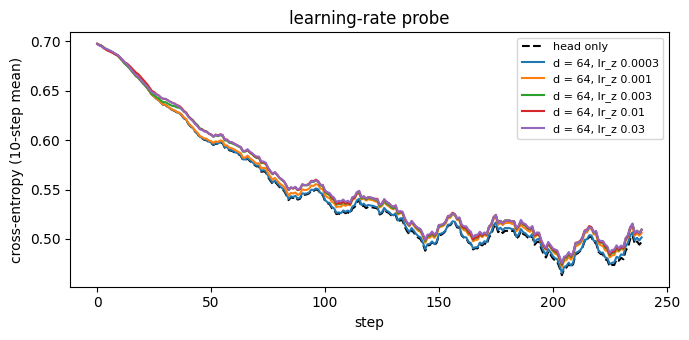

In [12]:
# 4.2 Learning-rate probe for z (runs once)
choice_path = M2B_DIR / "lr_choice.json"
if choice_path.exists():
    choice = json.loads(choice_path.read_text())
    print("using the stored learning-rate choice:", choice_path)
else:
    batch_iter = iter(train_loader)
    probe_batches = []
    for _ in range(PROBE_BATCHES):
        x, y, _ = next(batch_iter)
        probe_batches.append((x.to(DEVICE, torch.bfloat16), y.to(DEVICE)))
    del batch_iter
    curves = {}
    for lr_z in [0.0] + LR_Z_GRID:
        reset_head()
        adapter = None if lr_z == 0 else LatentAdapter(PROBE_D)
        optimizer = make_optimizer(adapter)
        ce = []
        for s in tqdm(range(PROBE_STEPS), desc="head only" if lr_z == 0 else f"lr_z {lr_z:g}", leave=False):
            x, y = probe_batches[s % PROBE_BATCHES]
            parts, _ = train_step(adapter, optimizer, x, y, {"head": LR_HEAD_MAX, "latent": lr_z})
            ce.append(parts["ce"])
        curves["head only" if lr_z == 0 else str(lr_z)] = ce
        del adapter, optimizer
    reset_head()
    del probe_batches
    torch.cuda.empty_cache()
    tail = PROBE_STEPS // 4
    scores = {k: float(np.mean(c[-tail:])) for k, c in curves.items()}
    latent_scores = {k: v for k, v in scores.items() if k != "head only" and np.isfinite(v)}
    best = min(latent_scores, key=latent_scores.get)
    choice = {"lr_z_max": float(best), "lr_z_min": float(best) / LR_RATIO, "probe_d": PROBE_D,
              "probe_steps": PROBE_STEPS, "mean_ce_last_quarter": scores, "curves": curves}
    choice_path.write_text(json.dumps(choice, indent=1))

LR_Z_MAX, LR_Z_MIN = choice["lr_z_max"], choice["lr_z_min"]
scores = choice["mean_ce_last_quarter"]
display(pd.Series(scores, name="mean cross-entropy, last quarter").to_frame().T)
print(f"chosen for z: LR_Z_MAX = {LR_Z_MAX:g}, LR_Z_MIN = {LR_Z_MIN:g}  (head: {LR_HEAD_MAX:g} -> {LR_HEAD_MIN:g})")
if LR_Z_MAX in (min(LR_Z_GRID), max(LR_Z_GRID)):
    print("NOTE: the best learning rate is at the edge of LR_Z_GRID; the true optimum may lie outside it")
if scores[str(LR_Z_MAX)] >= scores["head only"]:
    print("NOTE: in the probe no latent learning rate beats the head alone")

fig, ax = plt.subplots(figsize=(7, 3.5))
for k, c in choice["curves"].items():
    ax.plot(pd.Series(c).rolling(10, min_periods=1).mean(), label=k if k == "head only" else f"d = {PROBE_D}, lr_z {float(k):g}",
            color="black" if k == "head only" else None, linestyle="--" if k == "head only" else "-")
ax.set_xlabel("step")
ax.set_ylabel("cross-entropy (10-step mean)")
ax.set_title("learning-rate probe")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4.3 The runs (resumable)

For each entry of `RUNS`: 10 epochs, then the test set. Per run folder (`runs/m2b/head_only_...` or `runs/m2b/latent_ln_d<d>_...`): `config.json`, `epoch_XX.pt` and `last.pt` (head, z, α, optimizer, history), `test_predictions.csv`, `results.json`, and `payload.json` (the deployable model: head weights, z, α, seeds).

- **Resuming:** run 1.1 → 4.2 (skip 2.4 if you like; 4.2 reloads the stored choice), then this cell. Finished runs are skipped; an interrupted run continues after its last finished epoch.
- `CE real / DF / ...` are the training cross-entropies per generator, as in M1/M2.

In [13]:
# 4.3 The runs (resumable)
def run_dir_for(d):
    tag = "head_only" if d == 0 else f"latent_ln_d{d}"
    return M2B_DIR / f"{tag}_{ARCH}_train-{'-'.join(SHORT[g] for g in TRAIN_GENERATORS)}_seed{SEED}"


def run_label(d):
    return "head only" if d == 0 else f"latent LN d = {d}"


def train_run(d):
    run_dir = run_dir_for(d)
    run_dir.mkdir(parents=True, exist_ok=True)
    adapter = None if d == 0 else LatentAdapter(d)
    config = {**COMMON_CONFIG, "d": d}
    if adapter is not None:
        config.update({"w_seed": W_SEED, "w_entries": "N(0, 1/d)", "z_init": 0.0, "alpha_init": 1.0,
                       "lr_z_max": LR_Z_MAX, "lr_z_min": LR_Z_MIN, "w_fingerprint": w_fingerprint(adapter.W)})
    check_config(run_dir, config)
    reset_head()
    optimizer = make_optimizer(adapter)
    history, start_epoch = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        reset_head(ckpt["head"])
        if adapter is not None:
            adapter.load_latent(ckpt["latent"])
        optimizer.load_state_dict(ckpt["optimizer"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
    print(f"\n===== {run_label(d)}: {start_epoch}/{EPOCHS} epochs done =====")

    def state():
        return {"head": head_state(), "latent": None if adapter is None else adapter.latent_state()}

    steps_per_epoch = len(train_loader)
    for epoch in range(start_epoch, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n_steps, t0 = defaultdict(float), 0, time.time()
        ce_sum = torch.zeros(len(CATEGORIES), device=DEVICE)
        ce_cnt = torch.zeros(len(CATEGORIES), device=DEVICE)
        for i, (x, y, g) in enumerate(tqdm(train_loader, desc=f"{run_label(d)} epoch {epoch + 1}/{EPOCHS}", leave=False)):
            step = epoch * steps_per_epoch + i
            lrs = {"head": lr_at(step, steps_per_epoch, LR_HEAD_MAX, LR_HEAD_MIN),
                   "latent": lr_at(step, steps_per_epoch, LR_Z_MAX, LR_Z_MIN)}
            x, y, g = (t.to(DEVICE, non_blocking=True) for t in (x, y, g))
            parts, ce_each = train_step(adapter, optimizer, x, y, lrs)
            for k, v in parts.items():
                sums[k] += v
            ce_sum += torch.bincount(g, weights=ce_each, minlength=len(CATEGORIES))
            ce_cnt += torch.bincount(g, minlength=len(CATEGORIES))
            n_steps += 1

        val_table = metrics_table(predict(current_theta(adapter), val_df, images["val"], desc="val"))
        row = {"epoch": epoch + 1, "lr head (end)": lrs["head"]}
        row.update({k: v / n_steps for k, v in sums.items()})
        row.update({f"CE {SHORT[c]}": float(ce_sum[k] / ce_cnt[k]) for k, c in enumerate(CATEGORIES) if ce_cnt[k] > 0})
        if adapter is not None:
            row.update({"alpha": adapter.alpha.item(), "|z|": adapter.z.norm().item()})
        row.update({"val frame AUC": float(val_table["frame AUC"].iloc[0]),
                    "val video AUC": float(val_table["video AUC"].iloc[0]),
                    "minutes": (time.time() - t0) / 60})
        history.append(row)
        save_atomic(state(), run_dir / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, **state(), "optimizer": optimizer.state_dict(), "history": history},
                    run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

    if not (run_dir / "results.json").exists():
        pred = predict(current_theta(adapter), test_df, images["test"], desc="test")
        pred.to_csv(run_dir / "test_predictions.csv", index=False)
        table = metrics_table(pred)
        display(table)
        payload = {"arch": ARCH, "pretrained": PRETRAINED, "d": d,
                   "head": {k: v.tolist() for k, v in head_state().items()}}
        if adapter is not None:
            payload.update({"w_seed": W_SEED, "w_entries": "N(0, 1/d)", "latent_on": "LayerNorm only",
                            "alpha": adapter.alpha.item(), "z": adapter.z.tolist()})
        (run_dir / "payload.json").write_text(json.dumps(payload))
        (run_dir / "results.json").write_text(json.dumps(
            {"d": d, "test": table.to_dict(orient="records"), "history": history}, indent=1))
    del adapter, optimizer
    torch.cuda.empty_cache()


for d in RUNS:
    train_run(d)
reset_head()
print("all runs finished")


===== head only: 10/10 epochs done =====

===== latent LN d = 64: 10/10 epochs done =====

===== latent LN d = 1024: 10/10 epochs done =====

===== latent LN d = 256: 10/10 epochs done =====

===== latent LN d = 4096: 10/10 epochs done =====
all runs finished


## 5. Evaluation

### 5.1 Full LN tuning (M1) through the same code

M1's checkpoints at epoch 10 and 20, scored with M2b's code (LayerNorms through `write_theta`, head loaded into the trainable head). Epoch 20 must reproduce FaceShifter 88.37, which also checks the head handling.

In [14]:
# 5.1 Full LN tuning (M1) through the same code
def m1_model(epoch):
    state = load(M1_RUN_DIR / f"epoch_{epoch:02d}.pt")
    theta = torch.cat([state[n].reshape(-1).float() for n in TARGET_NAMES]).to(DEVICE)
    return theta, {"weight": state["head.weight"], "bias": state["head.bias"]}


ref_path = M2B_DIR / "m1_reference.json"
if ref_path.exists():
    m1_ref = json.loads(ref_path.read_text())
else:
    m1_ref = {}
    for e in (10, 20):
        theta, head = m1_model(e)
        reset_head(head)
        m1_ref[str(e)] = metrics_table(predict(theta, test_df, images["test"], desc=f"M1 epoch {e}")).to_dict(orient="records")
    reset_head()
    ref_path.write_text(json.dumps(m1_ref, indent=1))

for e in ("10", "20"):
    print(f"\n=== M1 full LN tuning, epoch {e} ===")
    display(pd.DataFrame(m1_ref[e]))
fsh_20 = pd.DataFrame(m1_ref["20"]).set_index("test set").loc["FaceShifter", "video AUC"]
print(f"epoch 20 FaceShifter video AUC: {fsh_20:.2f} (M1 notebook: 88.37) ->",
      "MATCH" if abs(fsh_20 - 88.37) < 0.3 else "MISMATCH: send the notebook before going on")


=== M1 full LN tuning, epoch 10 ===


,test set,status,frame AUC,video AUC,video acc @0.5,real / fake videos
0,seen combined (DF+F2F+FS+NT),seen,95.66,97.60,93.14,140 / 560
1,Deepfakes,seen,98.17,99.22,95.36,140 / 140
2,Face2Face,seen,96.06,98.09,93.21,140 / 140
3,FaceSwap,seen,98.15,99.20,95.71,140 / 140
4,NeuralTextures,seen,90.25,93.88,87.86,140 / 140
5,FaceShifter,UNSEEN,81.20,88.19,73.21,140 / 140



=== M1 full LN tuning, epoch 20 ===


,test set,status,frame AUC,video AUC,video acc @0.5,real / fake videos
0,seen combined (DF+F2F+FS+NT),seen,96.36,98.04,93.57,140 / 560
1,Deepfakes,seen,98.40,99.39,95.71,140 / 140
2,Face2Face,seen,96.78,98.40,93.21,140 / 140
3,FaceSwap,seen,98.54,99.38,95.71,140 / 140
4,NeuralTextures,seen,91.71,94.98,88.57,140 / 140
5,FaceShifter,UNSEEN,81.98,88.37,73.57,140 / 140


epoch 20 FaceShifter video AUC: 88.37 (M1 notebook: 88.37) -> MATCH


### 5.2 Results: head only, latent LayerNorms, full LN tuning (and M2 for contrast)

One row per model. **% gap recovered** = (AUC − head only) / (full LN, epoch 10 − head only) × 100: 0% means the latent adds nothing over the head alone, 100% means it matches full LN tuning. The figure shows video AUC against d for M2b (head trained directly) and M2 (head inside the latent), with head-only and full LN tuning as horizontal lines.

,d,trainable,seen video AUC,seen frame AUC,DF video AUC,F2F video AUC,FS video AUC,NT video AUC,FSh video AUC,FSh frame AUC,% gap recovered (seen),% gap recovered (FSh)
model,,,,,,,,,,,,
"M1 full LN tuning, epoch 10",102400,104450,97.60,95.66,99.22,98.09,99.20,93.88,88.19,81.20,100.00,100.00
"M1 full LN tuning, epoch 20",102400,104450,98.04,96.36,99.39,98.40,99.38,94.98,88.37,81.98,103.17,101.71
M2b head only,0,2050,83.71,81.64,97.95,81.59,96.34,58.96,77.65,74.34,0.00,0.00
M2b latent LN d = 64,64,2115,81.24,78.70,97.09,75.95,93.75,58.16,74.40,70.72,-17.78,-30.83
M2b latent LN d = 256,256,2307,77.28,73.30,93.13,71.93,86.67,57.40,68.64,64.94,-46.29,-85.48
M2b latent LN d = 1024,1024,3075,80.81,78.26,96.34,75.44,90.71,60.73,75.16,70.85,-20.88,-23.62
M2b latent LN d = 4096,4096,6147,91.07,87.51,99.55,91.65,97.97,75.11,81.54,75.85,52.99,36.91
"M2 latent LN + head, d = 16",16,17,50.11,49.98,51.44,48.08,48.45,52.47,58.29,56.95,-241.90,-183.68
"M2 latent LN + head, d = 64",64,65,46.56,47.11,43.08,52.51,41.25,49.40,55.56,53.49,-267.46,-209.58


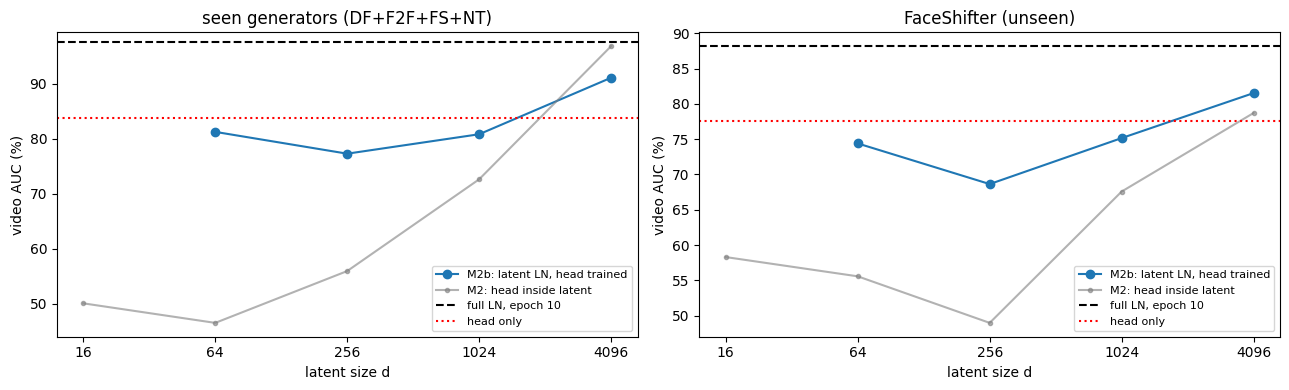

In [15]:
# 5.2 Results
def summary_row(model_name, d, trainable, records):
    t = pd.DataFrame(records).set_index("test set")
    row = {"model": model_name, "d": d, "trainable": trainable,
           "seen video AUC": t.iloc[0]["video AUC"], "seen frame AUC": t.iloc[0]["frame AUC"]}
    row.update({f"{SHORT[g]} video AUC": t.loc[g, "video AUC"] for g in ALL_GENERATORS})
    row["FSh frame AUC"] = t.loc["FaceShifter", "frame AUC"]
    return row


rows = [summary_row("M1 full LN tuning, epoch 10", P, P + HEAD_N, m1_ref["10"]),
        summary_row("M1 full LN tuning, epoch 20", P, P + HEAD_N, m1_ref["20"])]
m2b_results = {}
for d in sorted(RUNS):
    path = run_dir_for(d) / "results.json"
    if path.exists():
        m2b_results[d] = json.loads(path.read_text())
        rows.append(summary_row(f"M2b {run_label(d)}", d, HEAD_N + (d + 1 if d else 0), m2b_results[d]["test"]))
    else:
        print(f"{run_label(d)}: not finished yet")
m2_results = {}
for d in [16, 64, 256, 1024, 4096]:
    path = M2_DIR / f"latent_d{d}_{ARCH}_train-{'-'.join(SHORT[g] for g in TRAIN_GENERATORS)}_seed{SEED}" / "results.json"
    if path.exists():
        m2_results[d] = json.loads(path.read_text())
        rows.append(summary_row(f"M2 latent LN + head, d = {d}", d, d + 1, m2_results[d]["test"]))
table = pd.DataFrame(rows).set_index("model")

if 0 in m2b_results:
    full, head = table.loc["M1 full LN tuning, epoch 10"], table.loc["M2b head only"]
    for col in ["seen video AUC", "FSh video AUC"]:
        table[f"% gap recovered ({col.split()[0]})"] = 100 * (table[col] - head[col]) / (full[col] - head[col])
display(table.round(2))
(M2B_DIR / "summary.csv").write_text(table.to_csv())

latent_ds = sorted(d for d in m2b_results if d > 0)
if latent_ds:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, col, title in [(axes[0], "seen video AUC", "seen generators (DF+F2F+FS+NT)"),
                           (axes[1], "FSh video AUC", "FaceShifter (unseen)")]:
        ax.plot(latent_ds, [table.loc[f"M2b latent LN d = {d}", col] for d in latent_ds], marker="o",
                label="M2b: latent LN, head trained")
        if m2_results:
            m2_ds = sorted(m2_results)
            ax.plot(m2_ds, [table.loc[f"M2 latent LN + head, d = {d}", col] for d in m2_ds], marker=".",
                    color="gray", alpha=0.6, label="M2: head inside latent")
        ax.axhline(table.loc["M1 full LN tuning, epoch 10", col], color="black", linestyle="--", label="full LN, epoch 10")
        if 0 in m2b_results:
            ax.axhline(table.loc["M2b head only", col], color="red", linestyle=":", label="head only")
        ticks = sorted(set(latent_ds) | set(m2_results))
        ax.set_xscale("log", base=2)
        ax.set_xticks(ticks, [str(d) for d in ticks])
        ax.set_xlabel("latent size d")
        ax.set_ylabel("video AUC (%)")
        ax.set_title(title)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### 5.3 Training curves

Left: FF++ val video AUC per epoch (8 frames per video; M1 used 32). Middle: training cross-entropy. Right: final training cross-entropy per generator for every run; the spread between generators is what E1 (M3) measures.

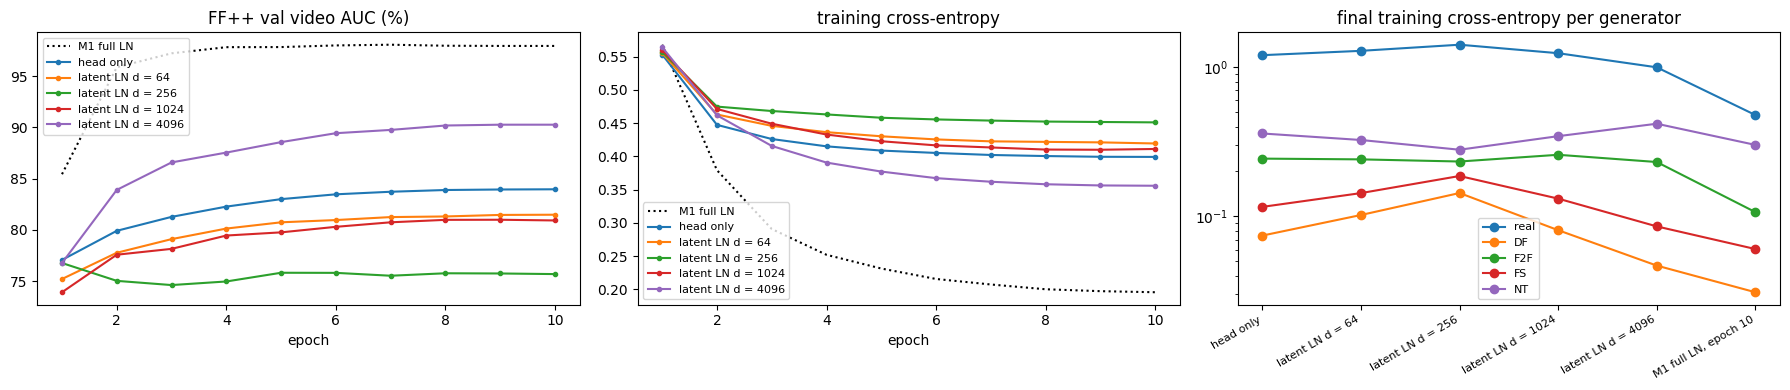

final training cross-entropy per generator:


,CE real,CE DF,CE F2F,CE FS,CE NT
head only,1.2021,0.0744,0.2438,0.1158,0.3593
latent LN d = 64,1.2852,0.1022,0.2410,0.1433,0.3249
latent LN d = 256,1.4126,0.1435,0.2332,0.1865,0.2796
latent LN d = 1024,1.2393,0.0809,0.2587,0.1316,0.3447
latent LN d = 4096,0.9970,0.0468,0.2314,0.0857,0.4176
"M1 full LN, epoch 10",0.4777,0.0311,0.1069,0.0605,0.3013


In [16]:
# 5.3 Training curves
assert m2b_results, "no finished runs yet (run 4.3)"
m1_hist = pd.DataFrame(load(M1_RUN_DIR / "last.pt")["history"]).iloc[:EPOCHS]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(m1_hist.epoch, m1_hist["val video AUC"], color="black", linestyle=":", label="M1 full LN")
axes[1].plot(m1_hist.epoch, m1_hist["ce"], color="black", linestyle=":", label="M1 full LN")
for d, res in sorted(m2b_results.items()):
    h = pd.DataFrame(res["history"])
    axes[0].plot(h.epoch, h["val video AUC"], marker=".", label=run_label(d))
    axes[1].plot(h.epoch, h["ce"], marker=".", label=run_label(d))
axes[0].set_title("FF++ val video AUC (%)")
axes[1].set_title("training cross-entropy")
for ax in axes[:2]:
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)

ce_cols = [f"CE {SHORT[c]}" for c in CATEGORIES if f"CE {SHORT[c]}" in m1_hist.columns]
final_ce = pd.DataFrame({run_label(d): pd.DataFrame(r["history"]).iloc[-1][ce_cols] for d, r in sorted(m2b_results.items())}).T
final_ce.loc["M1 full LN, epoch 10"] = m1_hist.iloc[-1][ce_cols]
final_ce = final_ce.astype(float)
for c in ce_cols:
    axes[2].plot(range(len(final_ce)), final_ce[c], marker="o", label=c[3:])
axes[2].set_xticks(range(len(final_ce)), final_ce.index, rotation=30, ha="right", fontsize=8)
axes[2].set_yscale("log")
axes[2].set_title("final training cross-entropy per generator")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("final training cross-entropy per generator:")
display(final_ce.round(4))

## 6. Send results back

1. Save this notebook (Ctrl+S) with its outputs.
2. From the repository folder on C-DAC:

```bash
git pull
git add M2b.ipynb
git commit -m "M2b run outputs"
git push
```

When git asks for a password, paste your GitHub token. Do not put the token in this notebook or any file, and do not send it to me. Runs stay in `runs/m2b/` on C-DAC.

**Order:** run all cells top to bottom (about 6.5 h; 4.3 resumes across sessions). Push early only if an assert fails, 5.1 says MISMATCH, or 4.2 prints a NOTE.

**What M2b hands on:** whether a small latent on the LayerNorms (with a shared trained head) is expressive enough for GBLA, the d to use in M3/M4, and the pooled latent solution at that d (`runs/m2b/latent_ln_d<d>_.../epoch_10.pt`) that E1 analyses.